# 1. Diagnóstico sobre Bronze
Primera mirada a los datos sin retocar: dimensiones, tipos, muestra y faltantes.

In [1]:
# 1) Importamos las librerías con sus alias convencionales
import pandas as pd                 # tablas (DataFrame)
import numpy as np                  # cálculo numérico y condiciones vectorizadas
import matplotlib.pyplot as plt     # gráficos base (Seaborn se apoya en él)
import seaborn as sns               # gráficos estadísticos de alto nivel
from scipy import stats             # pruebas estadísticas (Parte 6)

from flows.common.paths import BRONZE, SILVER, GOLD, BRONZE_LABELED_NAME, SILVER_NAME

# 2) Estilo global: todos los gráficos heredan esta configuración
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.figsize'] = (8, 5)
plt.rcParams['axes.titlesize'] = 13

# 3) Cargamos Bronze (nunca la URL: la ingesta ya la guardó)
df = pd.read_csv(BRONZE / BRONZE_LABELED_NAME)

## Paso 1. Dimensiones
¿Cuántos pasajeros (filas) y variables (columnas) hay?

In [2]:
# shape es un ATRIBUTO: devuelve (filas, columnas)
df.shape

(891, 12)

## Paso 2. Variables y tipos
Comparamos los no nulos de cada columna con el total de filas (891) para detectar faltantes.

In [3]:
# info() es un MÉTODO: imprime nombre, no nulos y tipo de cada columna
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    float64
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(3), int64(4), str(5)
memory usage: 118.9 KB


## Paso 3. Primeras 10 filas

In [4]:
df.head(10)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0.0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1.0,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1.0,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1.0,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0.0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
5,6,0.0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q
6,7,0.0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S
7,8,0.0,3,"Palsson, Master. Gosta Leonard",male,2.0,3,1,349909,21.0750,NaN,S
8,9,1.0,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,0,2,347742,11.1333,NaN,S
9,10,1.0,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0,1,0,237736,30.0708,NaN,C


## Paso 4. Estadísticas descriptivas

In [5]:
# Columnas numéricas: conteo, media, desviación, mínimo, cuartiles, máximo
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [6]:
# Columnas NO numéricas: conteo, valores únicos, más frecuente (top) y su frecuencia
df.select_dtypes(exclude='number').describe()

,Name,Sex,Ticket,Cabin,Embarked
count,891,891,891,204,889
unique,891,2,681,147,3
top,"Braund, Mr. Owen Harris",male,347082,G6,S
freq,1,577,7,4,644


## Paso 5. Datos faltantes

In [7]:
# Conteo de nulos por columna (True cuenta como 1)
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

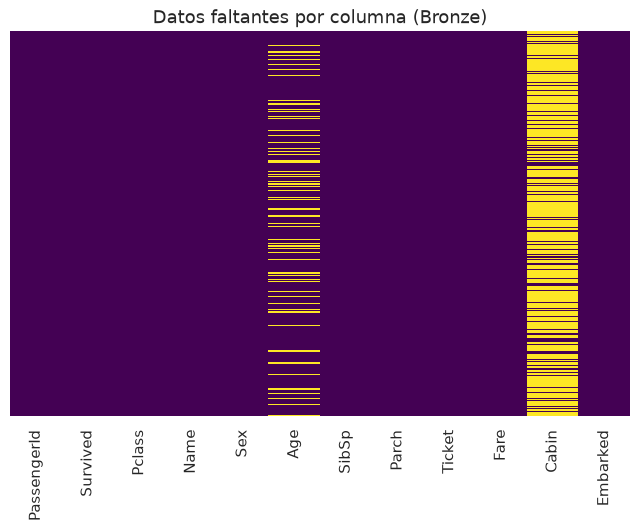

In [8]:
# Mapa de calor: cada línea amarilla es un dato faltante
sns.heatmap(df.isnull(), cbar=False, yticklabels=False, cmap='viridis')
plt.title('Datos faltantes por columna (Bronze)')
plt.show()

# 2. Conociendo a los pasajeros (Silver)
A partir de aquí el cuaderno lee la capa Silver.

In [10]:
# Recargamos desde Silver (incluye la columna Person creada en el módulo)
df = pd.read_parquet(SILVER / SILVER_NAME)
df.shape

(891, 13)

## Paso 6. Distribución por género y su cruce con la clase

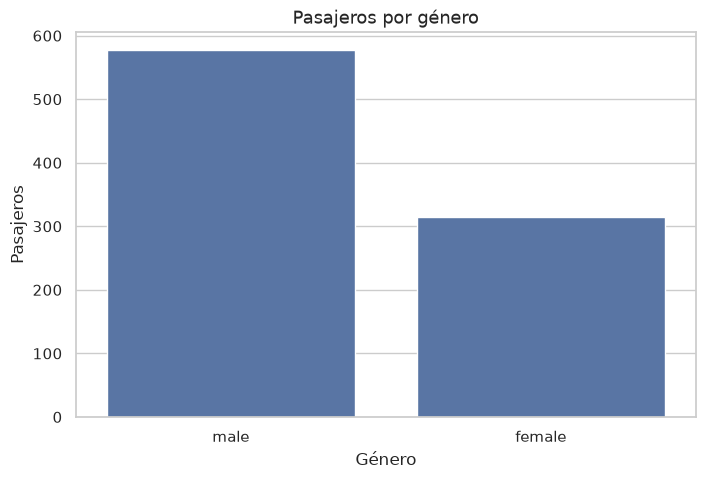

In [11]:
sns.countplot(data=df, x='Sex')
plt.title('Pasajeros por género'); plt.xlabel('Género'); plt.ylabel('Pasajeros')
plt.show()

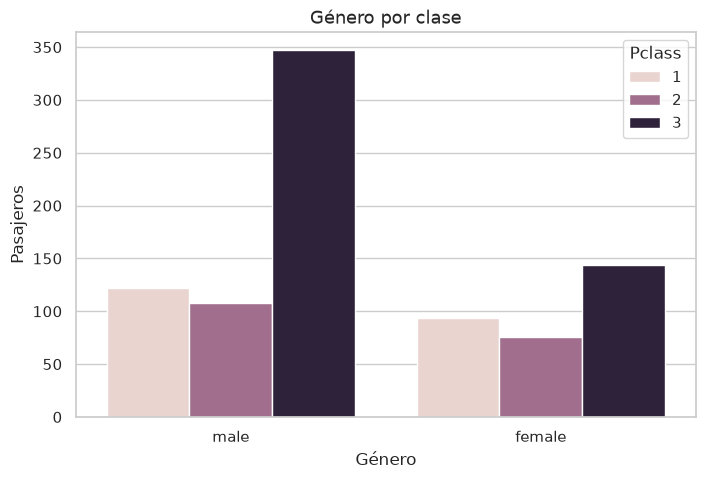

In [12]:
sns.countplot(data=df, x='Sex', hue='Pclass')
plt.title('Género por clase'); plt.xlabel('Género'); plt.ylabel('Pasajeros')
plt.show()

In [13]:
# Proporción de cada género DENTRO de cada clase (cada columna suma 1)
pd.crosstab(df['Sex'], df['Pclass'], normalize='columns').round(3)

Pclass,1,2,3
Sex,,,
female,0.435,0.413,0.293
male,0.565,0.587,0.707


## Paso 7. Distribución de edades
Age todavía no está imputada en Silver: solo vemos pasajeros con edad conocida.

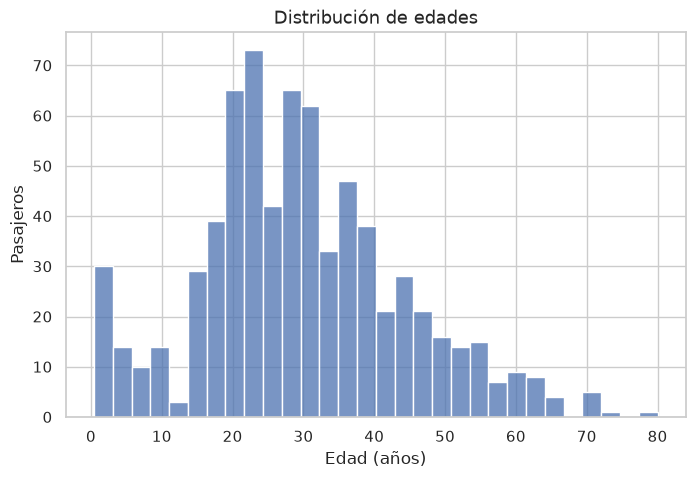

In [14]:
sns.histplot(df['Age'].dropna(), bins=30)
plt.title('Distribución de edades'); plt.xlabel('Edad (años)'); plt.ylabel('Pasajeros')
plt.show()

In [15]:
# Edad promedio (Pandas ignora los NaN)
df['Age'].mean()

np.float64(29.69911764705882)

In [16]:
# Mediana, mínimo y máximo
df['Age'].median(), df['Age'].min(), df['Age'].max()

(np.float64(28.0), np.float64(0.42), np.float64(80.0))

## Paso 8. Variable Person (hombre, mujer o niño)
Creada en `flows/01_data_engineering.py` → `add_person`. Un pasajero sin edad nunca es `child`: conserva su sexo.

In [17]:
df['Person'].value_counts()

Person
male      537
female    271
child      83
Name: count, dtype: int64

### Reto 8.1. ¿Cuántos niños "faltan" por edad desconocida?

In [18]:
n_sin_edad = df['Age'].isnull().sum()

# Proporción de niños entre quienes SÍ tienen edad
con_edad = df[df['Age'].notna()]
prop_ninos = (con_edad['Person'] == 'child').mean()

ninos_faltantes = n_sin_edad * prop_ninos
print(f'Pasajeros sin edad: {n_sin_edad}')
print(f'Proporción de niños entre los que tienen edad: {prop_ninos:.3f}')
print(f'Niños que probablemente "faltan": {ninos_faltantes:.0f}')

Pasajeros sin edad: 177
Proporción de niños entre los que tienen edad: 0.116
Niños que probablemente "faltan": 21


## Paso 9. ¿Cuántos niños viajaban en cada clase?

In [19]:
pd.crosstab(df['Pclass'], df['Person'])

Person,child,female,male
Pclass,,,
1,6,91,119
2,19,66,99
3,58,114,319


## Paso 10. Densidad (KDE) de la edad
`common_norm=False` normaliza cada grupo por separado para que los grupos grandes no aplasten a los pequeños.

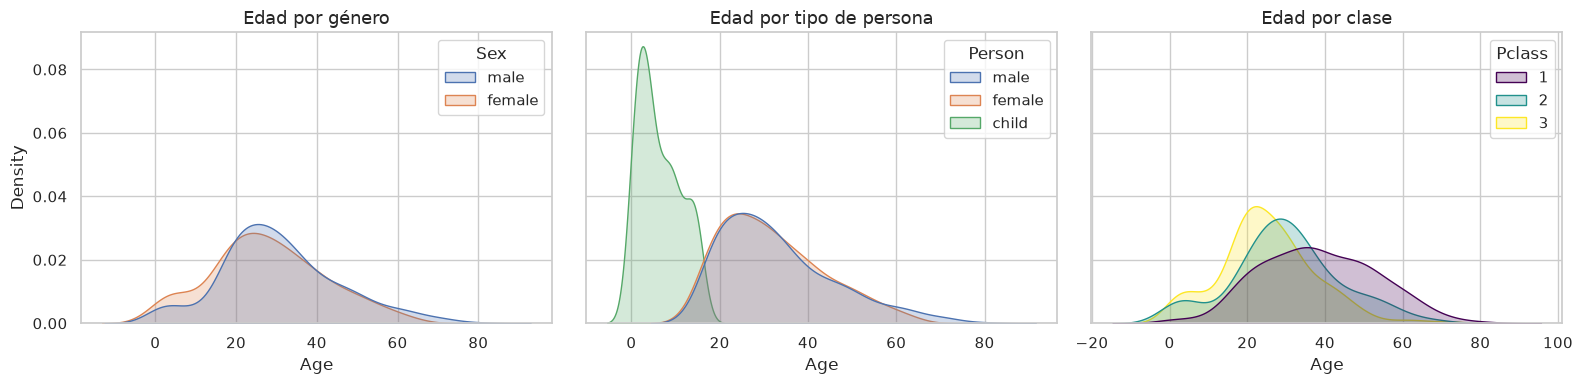

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
sns.kdeplot(data=df, x='Age', hue='Sex', fill=True, common_norm=False, ax=axes[0])
sns.kdeplot(data=df, x='Age', hue='Person', fill=True, common_norm=False, ax=axes[1])
sns.kdeplot(data=df, x='Age', hue='Pclass', fill=True, common_norm=False,
            palette='viridis', ax=axes[2])
axes[0].set_title('Edad por género')
axes[1].set_title('Edad por tipo de persona')
axes[2].set_title('Edad por clase')
plt.tight_layout(); plt.show()